### Imports

In [1]:
import json
from pathlib import Path

import numpy as np

from experiments._common import H4_FCIDUMP_PATH, H4_FCI_ENERGY

from qcmps import (
    FCIDumpLoader,
    GlobalQCMPS, Ansatz, HFPreset,
    Logger,
    TwoSiteOptimizer,
    SO4Gate, StarLayerType,
    Observable,
)
from qcmps.layers import LUBondConnectedLayerType

### Configuration and logger

In [28]:
RUN_A = 6
RUN_B = 7

output_h4 = Path.cwd() / "output"
output_dir = Path.cwd() / "output_test"
output_dir.mkdir(exist_ok=True)

name = f"h4_connected_star_{RUN_A}_{RUN_B}"
checkpoint_path = output_dir / f"{name}_check.json"
logging_path = output_dir / f"{name}.log"
value_path = output_dir / f"{name}.csv"

logger = Logger(logging_path, value_file=value_path, continue_logging=False)

### Loading the system from FCIDump

In [29]:
loader = FCIDumpLoader(H4_FCIDUMP_PATH)
loader.interleave_spin_orbitals()

hamiltonian_operator = loader.hamiltonian
nuclear_repulsion = loader.nuclear_repulsion
hf_occupancy = loader.hf_occupancy()

num_phys_qubits = loader.n_spin_orbitals
num_bond_qubits = 2
num_qubits = num_phys_qubits + num_bond_qubits

physical_qubits = list(range(num_phys_qubits))
bond_qubits = list(range(num_phys_qubits, num_qubits))
input_physical_qubits = list(range(num_bond_qubits, num_qubits))

### Loading the pretrained q=1 parameters

In [30]:
def load_qcmps_parameters(path: Path) -> np.ndarray:
    with path.open(encoding="utf-8") as file:
        checkpoint = json.load(file)

    qcmps_data = next(
        component
        for component in checkpoint["components"]
        if component["type"] == "GlobalQCMPS"
    )

    parameters = np.asarray(qcmps_data["parameters_values"], dtype=float)
    expected_parameters = num_phys_qubits * SO4Gate.n_parameters()

    if parameters.size != expected_parameters:
        raise ValueError(
            f"Expected {expected_parameters} q=1 parameters in {path}, "
            f"got {parameters.size}."
        )

    return parameters.reshape(num_phys_qubits, SO4Gate.n_parameters())

parameters_a = load_qcmps_parameters(output_h4 / f"h4_{RUN_A}_check.json")
parameters_b = load_qcmps_parameters(output_h4 / f"h4_{RUN_B}_check.json")

### Building the connected Star ansatz

In [31]:
star_a_layer = StarLayerType(SO4Gate, center_qubit=0, target_qubits=[1])
bond_connector_layer = LUBondConnectedLayerType(SO4Gate, bond_qubits=[1, 2])
star_b_layer = StarLayerType(SO4Gate, center_qubit=0, target_qubits=[2])

qcmps = GlobalQCMPS(
    num_phys_qubits,
    num_bond_qubits,
    [star_a_layer, bond_connector_layer, star_b_layer],
)

connector_parameters = np.zeros_like(parameters_a)
initial_parameters = np.concatenate((parameters_a, connector_parameters, parameters_b), axis=1,).reshape(-1)

qcmps.update_parameters(initial_parameters)

ansatz = Ansatz(num_qubits)
hf_preset = HFPreset(num_phys_qubits, hf_occupancy)

ansatz.add_component(hf_preset, input_physical_qubits)
ansatz.add_component(qcmps, list(range(num_qubits)))

### Defining the observables

In [32]:
hamiltonian = Observable(
    hamiltonian_operator,
    physical_qubits,
    constant=nuclear_repulsion,
    label="Total energy",
)
particle_number = Observable.particle_number(physical_qubits)
alpha_number = Observable.alpha_particle_number(physical_qubits)
beta_number = Observable.beta_particle_number(physical_qubits)

### Initial connected Star state

In [33]:
initial_energy = hamiltonian(ansatz)

logger.log(f"Connected Star initialization from runs {RUN_A} and {RUN_B}.")
logger.log(f"Initial total energy: {initial_energy:.12f}")
logger.log(f"Initial energy variance: {hamiltonian.var(ansatz):.12f}")
logger.log(f"Initial particle number: {particle_number(ansatz):.12f}")
logger.log(f"Initial particle number variance: {particle_number.var(ansatz):.12f}")
logger.log_value(hamiltonian.label, initial_energy, 1)

Connected Star initialization from runs 6 and 7.
Initial total energy: -2.215761431402
Initial energy variance: 0.071253662000
Initial particle number: 4.000554247104
Initial particle number variance: 0.001472109291


### Optimizing only the bond connector

In [34]:
connector_parameter_groups = qcmps.layer_parameter_groups(1)

logger.log("Starting bond connector optimization...")
connector_optimizer = TwoSiteOptimizer(
    logger,
    log_every_n_steps=None,
    max_sweeps=10,
    local_maxiter=10,
    tolerance=1e-8,
)
connector_result = connector_optimizer.optimize(
    ansatz,
    hamiltonian,
    qcmps,
    active_parameters=connector_parameter_groups,
)

Starting bond connector optimization...
[Optimizer] Sweep 1/10 started.
[Optimizer] [Sweep 1 Site pair 1-2] Total energy: -2.215888386550
[Optimizer] [Sweep 1 Site pair 2-3] Total energy: -2.218279965357
[Optimizer] [Sweep 1 Site pair 3-4] Total energy: -2.218385914759
[Optimizer] [Sweep 1 Site pair 4-5] Total energy: -2.218680845728
[Optimizer] [Sweep 1 Site pair 5-6] Total energy: -2.219746788943
[Optimizer] [Sweep 1 Site pair 6-7] Total energy: -2.220000238873
[Optimizer] [Sweep 1 Site pair 7-8] Total energy: -2.220254431431
[Optimizer] [Sweep 1 Site pair 6-7] Total energy: -2.220342535768
[Optimizer] [Sweep 1 Site pair 5-6] Total energy: -2.220621982350
[Optimizer] [Sweep 1 Site pair 4-5] Total energy: -2.220686243855
[Optimizer] [Sweep 1 Site pair 3-4] Total energy: -2.220797226169
[Optimizer] [Sweep 1 Site pair 2-3] Total energy: -2.221040569518
[Optimizer] [Sweep 1] Total energy: -2.221040569518, Relative change: 2.383e-03
[Optimizer] Sweep 2/10 started.
[Optimizer] [Sweep 2 Sit

### State after optimizing the connector

In [35]:
connector_energy = hamiltonian(ansatz)
logger.log(f"Energy after connector optimization: {connector_energy:.12f}")
logger.log(f"Connector energy improvement: {initial_energy - connector_energy:.12e}")

Energy after connector optimization: -2.224733786203
Connector energy improvement: 8.972354801667e-03


### Optimizing all QCMPS parameters

In [37]:
logger.log("Starting full Two site optimization...")
full_optimizer = TwoSiteOptimizer(
    logger,
    log_every_n_steps=None,
    max_sweeps=2,
    local_maxiter=10,
    tolerance=1e-8,
)
full_result = full_optimizer.optimize(ansatz, hamiltonian, qcmps)

Starting full Two site optimization...
[Optimizer] Sweep 1/2 started.
[Optimizer] [Sweep 1 Site pair 1-2] Total energy: -2.228587237633
[Optimizer] [Sweep 1 Site pair 2-3] Total energy: -2.228588116061
[Optimizer] [Sweep 1 Site pair 3-4] Total energy: -2.228601296704
[Optimizer] [Sweep 1 Site pair 4-5] Total energy: -2.228618360692
[Optimizer] [Sweep 1 Site pair 5-6] Total energy: -2.228627788659
[Optimizer] [Sweep 1 Site pair 6-7] Total energy: -2.228637292737
[Optimizer] [Sweep 1 Site pair 7-8] Total energy: -2.228638143215
[Optimizer] [Sweep 1 Site pair 6-7] Total energy: -2.228644133208
[Optimizer] [Sweep 1 Site pair 5-6] Total energy: -2.228651350734
[Optimizer] [Sweep 1 Site pair 4-5] Total energy: -2.228661237034
[Optimizer] [Sweep 1 Site pair 3-4] Total energy: -2.228664622498
[Optimizer] [Sweep 1 Site pair 2-3] Total energy: -2.228667862424
[Optimizer] [Sweep 1] Total energy: -2.228667862424, Relative change: 3.790e-05
[Optimizer] Sweep 2/2 started.
[Optimizer] [Sweep 2 Site p

### Logging important expectation values

In [38]:
final_energy = hamiltonian(ansatz)

logger.log(f"Final total energy: {final_energy:.12f}")
logger.log(f"Final energy variance: {hamiltonian.var(ansatz):.12f}")
logger.log(f"Particle number: {particle_number(ansatz):.12f}")
logger.log(f"Particle number variance: {particle_number.var(ansatz):.12f}")
logger.log(f"Alpha particle number: {alpha_number(ansatz):.12f}")
logger.log(f"Beta particle number: {beta_number(ansatz):.12f}")
logger.log(f"Absolute FCI error: {abs(final_energy - H4_FCI_ENERGY):.12e}")

Final total energy: -2.228704596824
Final energy variance: 0.050568000912
Particle number: 4.000004350830
Particle number variance: 0.000164090803
Alpha particle number: 1.999970895589
Beta particle number: 2.000033455241
Absolute FCI error: 2.725747654178e-02


### Saving the ansatz into checkpoint

In [39]:
ansatz.save_checkpoint(checkpoint_path)

### Plotting the energy

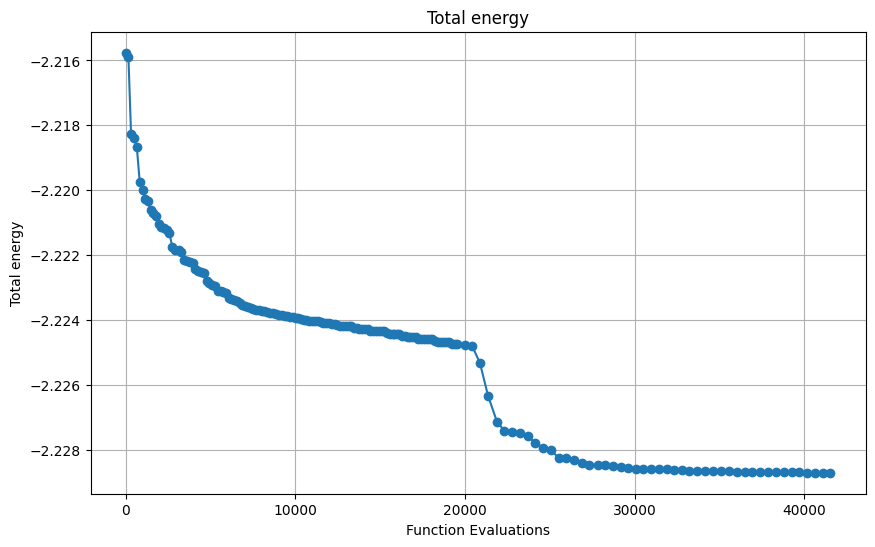

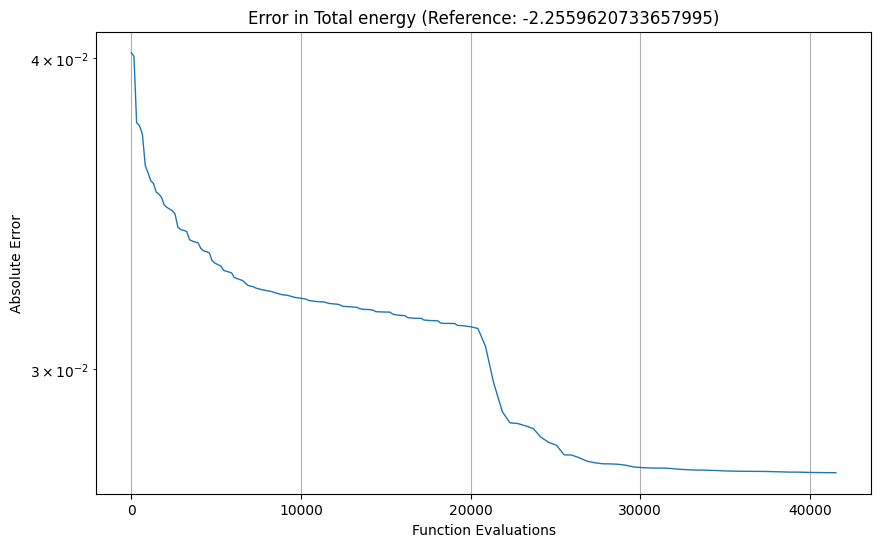

In [40]:
logger.plot_values(hamiltonian.label)
logger.plot_error(hamiltonian.label, H4_FCI_ENERGY, log_scale=True)